# Notebook 01 — Video Reading & Frame Processing

**Objective.** Understand how digital video is represented and build frame-reading logic that is *verified* to return the right frame, with the right index and timestamp, without skipping frames or losing track of the capture position.

**Background.** Every later component (detection, tracking, violation rules, evidence) consumes frames. If the reader silently skips a frame, mislabels its index, or returns frame 101 when asked for frame 100, every timestamp in a violation event inherits that error. This notebook establishes how OpenCV's `VideoCapture` behaves and checks it against ground truth.

**Input.**
- `data/video-test.mp4` — primary sample (H.264, 1920×1080, 59.94 FPS, 900 frames; see Notebook 00).
- `data/traffic_sample.mp4` — synthetic clip with the **frame number and time burned into every frame**, used as visual ground truth.
- `data/car-detection.mp4` — third clip, a different codec setting and frame rate (12.5 FPS) for the seeking checks.

**Output.**
- Verified facts about capture position, timestamps, seeking, and end-of-video behavior.
- Validated reading functions `open_video`, `read_video_metadata`, `iter_frames`, `read_frame_at`, `frame_index_at_time`, `read_frame_at_time`. Their records follow the **Frame Data** contract of the specification (video id, frame index, timestamp, image, width, height). After validation they were moved to `src/traffic_violation_detection/video.py` (with tests in `tests/test_video.py`); this notebook imports them from there.
- Figures and a JSON report in `outputs/01_video_reading/` (git-ignored).

This notebook supersedes the early draft `01_video_reader.ipynb`; that draft's open-and-check code is the starting point of section 2. Run it from a clean kernel with the `Python (tvd)` kernel.

## 0. Setup

In [1]:
import hashlib
import json
import time
import warnings
from fractions import Fraction
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

# Photographic frames compress poorly as PNG; JPEG keeps the saved notebook small.
%config InlineBackend.figure_formats = ["jpeg"]

print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 5.0.0 | NumPy 2.4.6


In [2]:
def find_project_root(start: Path) -> Path:
    # Same helper as Notebook 00: walk up until pyproject.toml is found.
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError(f"No pyproject.toml found in {start} or any parent directory")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "01_video_reading"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_VIDEO = DATA_DIR / "video-test.mp4"
SYNTHETIC_VIDEO = DATA_DIR / "traffic_sample.mp4"
OVERHEAD_VIDEO = DATA_DIR / "car-detection.mp4"
ALL_VIDEOS = [SAMPLE_VIDEO, SYNTHETIC_VIDEO, OVERHEAD_VIDEO]

for path in ALL_VIDEOS:
    assert path.is_file(), f"Missing input video: {path}"
print("Project root:", PROJECT_ROOT)

Project root: /workspace/traffic-violation-detection-system


## 1. Concepts: what a video file is

- **Frame.** A video is a sequence of still images (frames) shown at regular intervals. In OpenCV each decoded frame is a NumPy array.
- **FPS.** Frames per second. Frame *i* (counting from 0) is displayed from time `i / fps` until `(i + 1) / fps`. This assumes a **constant frame rate** (CFR); some cameras produce variable frame rate (VFR) video, where per-frame timestamps must come from the file instead.
- **Frame count and duration.** `duration = frame_count / fps`. Both numbers come from the file header and can be wrong. Notebook 00 showed they matched for our files, but a damaged file is checked in section 7.
- **Container and codec.** MP4 is a *container*; the frames inside are compressed by a *codec* (H.264 here). Most frames are stored as differences from earlier frames, and only periodic **keyframes** are self-contained. To show frame 500, the decoder must start at the nearest keyframe before it and decode forward. That is why random access ("seeking") is much slower than reading sequentially.
- **Capture position.** A `cv2.VideoCapture` object keeps an internal cursor. Every `read()` returns the frame at the cursor and moves it forward. Most frame-reading bugs come from losing track of this cursor.

## 2. Open a video and validate it

This is the open-and-check from the earlier draft. One change: the draft used the relative path `"../data/video-test.mp4"`, which only works when Jupyter's working directory is `notebooks/`. Here the path is built from the project root.

`cv2.VideoCapture` **does not raise an exception** when it cannot open a file; it returns an object whose `isOpened()` is `False`. The check is therefore mandatory.

In [3]:
cap = cv2.VideoCapture(str(SAMPLE_VIDEO))
if not cap.isOpened():
    raise RuntimeError(f"Failed to open the video: {SAMPLE_VIDEO}")

print("Opened:", cap.isOpened(), "| backend:", cap.getBackendName())

Opened: True | backend: FFMPEG


## 3. Read the metadata

`cap.get(...)` takes a numeric **property id**: the draft's `cap.get("")` failed because an empty string is not one. OpenCV provides the ids as constants such as `cv2.CAP_PROP_FPS`.

In [4]:
fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration_s = frame_count / fps

print(f"FPS         : {fps}  (= {Fraction(fps).limit_denominator(1001)})")
print(f"Frame count : {frame_count}")
print(f"Resolution  : {width} x {height}")
print(f"Duration    : {duration_s:.3f} s")

FPS         : 59.94005994005994  (= 60000/1001)
Frame count : 900
Resolution  : 1920 x 1080
Duration    : 15.015 s


59.94 FPS is exactly 60000/1001, a broadcast frame rate. Frame times are therefore not round numbers: one frame lasts 1001/60 ≈ 16.683 ms. Computing timestamps as `index / fps` handles this correctly. Accumulating a rounded "16.7 ms per frame" would drift.

## 4. Read a single frame and watch the position

`read()` returns a pair `(ok, frame)`. `ok` is `False` when no frame could be returned (end of video or decoding error), and then `frame` is `None`. We print the capture position before and after.

In [5]:
print("Before read: POS_FRAMES =", cap.get(cv2.CAP_PROP_POS_FRAMES), "| POS_MSEC =", cap.get(cv2.CAP_PROP_POS_MSEC))

ok, frame = cap.read()
if not ok:
    raise RuntimeError("Could not read the first frame")

print("After read : POS_FRAMES =", cap.get(cv2.CAP_PROP_POS_FRAMES), "| POS_MSEC =", cap.get(cv2.CAP_PROP_POS_MSEC))

Before read: POS_FRAMES = 0.0 | POS_MSEC = 0.0
After read : POS_FRAMES = 1.0 | POS_MSEC = 0.0


The two position properties describe different things after a `read()`:

- `CAP_PROP_POS_FRAMES` is the index of the **next** frame to be decoded (1 after reading frame 0).
- `CAP_PROP_POS_MSEC` is the timestamp of the frame **just returned** (0 ms for frame 0).

Mixing the two up produces an off-by-one error in frame indices. Section 6 confirms the pattern over more frames.

## 5. Inspect the frame's pixel data

In [6]:
print("type  :", type(frame).__name__)
print("shape :", frame.shape, "-> (height, width, channels)")
print("dtype :", frame.dtype, "| value range:", frame.min(), "-", frame.max())
print(f"memory: {frame.nbytes / 1e6:.1f} MB per frame -> {frame.nbytes * frame_count / 1e9:.1f} GB for all {frame_count} frames")

row, col = height // 2, width // 2
print(f"pixel at row {row}, col {col} (B, G, R):", frame[row, col])

type  : ndarray
shape : (1080, 1920, 3) -> (height, width, channels)
dtype : uint8 | value range: 0 - 255
memory: 6.2 MB per frame -> 5.6 GB for all 900 frames
pixel at row 540, col 960 (B, G, R): [45 36 85]


Three conventions to keep in mind for every later notebook:

- **Indexing is `frame[row, col]` = `frame[y, x]`.** OpenCV drawing functions and bounding boxes use points as `(x, y)`, the opposite order.
- **Channels are B, G, R**, not R, G, B.
- **One 1080p frame is about 6 MB.** The whole clip decoded would need several GB, so frames are processed one at a time (streamed), not loaded all at once.

## 6. BGR → RGB and visualization

Matplotlib interprets the last axis as R, G, B. Showing an OpenCV frame directly swaps red and blue.

same pixel (R, G, B): [85 36 45]


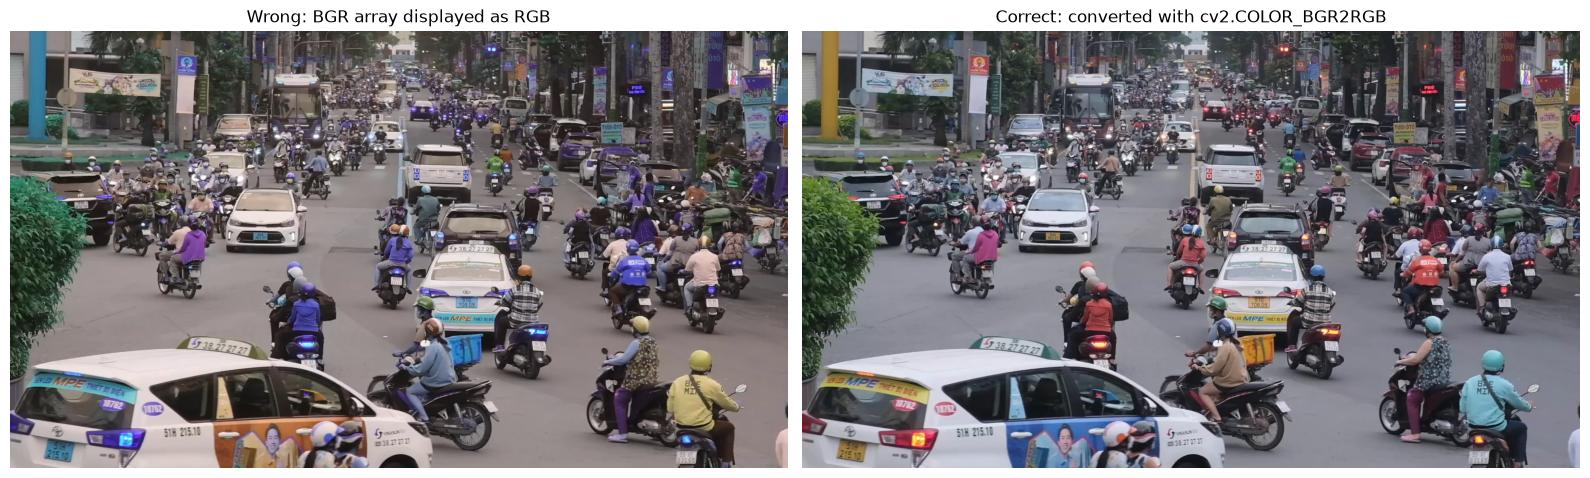

In [7]:
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

# The conversion is exactly a reversal of the channel axis.
assert np.array_equal(frame_rgb, frame[..., ::-1])
print(f"same pixel (R, G, B): {frame_rgb[row, col]}")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
axes[0].imshow(frame)
axes[0].set_title("Wrong: BGR array displayed as RGB")
axes[1].imshow(frame_rgb)
axes[1].set_title("Correct: converted with cv2.COLOR_BGR2RGB")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "bgr_vs_rgb.png", dpi=80)
plt.show()

## 7. The capture position is shared state

The capture `cap` is still open and its cursor is after frame 0. Each further `read()` moves it on. We keep our **own counter** of which frame was returned and compare it with both position properties.

In [8]:
returned_index = 0  # frame 0 was read in section 4
print("returned frame | POS_FRAMES after | POS_MSEC after | index / fps (ms)")
for _ in range(4):
    ok, _frame = cap.read()
    assert ok
    returned_index += 1
    print(f"{returned_index:14d} | {cap.get(cv2.CAP_PROP_POS_FRAMES):16.0f} | "
          f"{cap.get(cv2.CAP_PROP_POS_MSEC):14.3f} | {returned_index / fps * 1000:16.3f}")

returned frame | POS_FRAMES after | POS_MSEC after | index / fps (ms)
             1 |                2 |         16.683 |           16.683
             2 |                3 |         33.367 |           33.367
             3 |                4 |         50.050 |           50.050
             4 |                5 |         66.733 |           66.733


This is the pitfall the completion criterion warns about. A cell such as `ok, frame = cap.read()` returns a **different frame every time it is re-run**, and any other cell that reads from `cap` moves the same cursor. Results then depend on execution order, which breaks "run from a clean kernel".

From here on, therefore:

1. Every function opens its **own** capture and always releases it.
2. Frame indices come from our own counter. The position properties are only cross-checked against it, never trusted blindly.

We release the exploratory capture now. After `release()`, reads fail instead of raising an exception.

In [9]:
cap.release()
print("isOpened after release:", cap.isOpened())
print("read after release    :", cap.read()[0])

isOpened after release: False
read after release    : False


## 8. Reading helpers (now in `src/`)

These helpers were first written and validated in this notebook. Following specification §7.3 they now live in **`src/traffic_violation_detection/video.py`**, and the checks of section 12 also run as automated tests in `tests/test_video.py`. The notebook imports them, so there is a single implementation, and prints their source below.

They are deliberately small functions rather than classes. Each frame is returned as a plain dictionary following the **Frame Data** contract:

| key | meaning |
| --- | --- |
| `video_id` | file name without extension; identifies the source video |
| `frame_index` | 0-based index, from our own counter |
| `timestamp_s` | presentation time of this frame in seconds, as reported by the decoder |
| `width`, `height` | frame size in pixels |
| `image` | the BGR `uint8` array |

**Design decisions:**

- `open_video` is a **context manager**: `release()` runs even if the code inside the `with` block raises.
- `iter_frames` is a **generator** that yields one frame at a time, so memory stays constant.
- For `step > 1`, skipped frames use `grab()` (decode only) instead of `read()` (decode + convert). The decoder still has to process every frame, because frames depend on each other; `grab()` only avoids the conversion of frames we discard.
- When the video ends **earlier than the header promised**, `iter_frames` emits a warning instead of finishing silently.

In [10]:
import inspect

import traffic_violation_detection.video as video_module
from traffic_violation_detection.video import (
    frame_index_at_time,
    iter_frames,
    open_video,
    read_frame_at,
    read_frame_at_time,
    read_video_metadata,
)

print("Imported from:", video_module.__file__)
print()
print(inspect.getsource(open_video))
print(inspect.getsource(read_video_metadata))

Imported from: /workspace/traffic-violation-detection-system/src/traffic_violation_detection/video.py

@contextmanager
def open_video(path: str | Path) -> Iterator[cv2.VideoCapture]:
    """Open a video for reading and always release it when the with-block ends.

    Raises FileNotFoundError if ``path`` is not a file, and RuntimeError if
    OpenCV cannot open it (``cv2.VideoCapture`` itself never raises).
    """
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Video file not found (or not a file): {path}")
    capture = cv2.VideoCapture(str(path))
    try:
        if not capture.isOpened():
            raise RuntimeError(f"OpenCV could not open the video: {path}")
        yield capture
    finally:
        capture.release()

def read_video_metadata(path: str | Path) -> VideoMetadata:
    """Metadata as reported by the file header (not verified by decoding)."""
    with open_video(path) as capture:
        fps = capture.get(cv2.CAP_PROP_FPS)
        f

In [11]:
print(inspect.getsource(iter_frames))

def iter_frames(
    path: str | Path, start: int = 0, stop: int | None = None, step: int = 1
) -> Iterator[FrameRecord]:
    """Yield frames ``start, start + step, ...`` (``< stop``, or until the video ends).

    Skipped frames are only grabbed (decoded, not converted), which is cheaper
    than ``read()``. If the video ends before the frame count in its header,
    a warning is emitted instead of finishing silently (e.g. truncated files).
    """
    if start < 0 or step < 1 or (stop is not None and stop < start):
        raise ValueError(f"Invalid range: start={start}, stop={stop}, step={step}")
    path = Path(path)
    with open_video(path) as capture:
        reported = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
        if start > 0:
            capture.set(cv2.CAP_PROP_POS_FRAMES, start)
            landed = int(capture.get(cv2.CAP_PROP_POS_FRAMES))
            if landed != start:
                # OpenCV clamps seeks past the end to the last decodable position.
               

Random access reuses `iter_frames` with a one-frame range. Wrapping the generator in `closing(...)` makes it finish, and release its capture, immediately after the first frame instead of whenever it is garbage-collected.

**Converting a time to a frame index needs an explicit convention.** We use *the frame that is on screen at time t*: frame *i* is displayed during `[i / fps, (i + 1) / fps)`, so the index is `floor(t · fps)`.

A tiny epsilon guards against floating-point products that land just below an exact frame boundary. For example, 2.32 s × 12.5 FPS evaluates to `28.999999999999996`, although frame 29 starts exactly at 2.32 s.

In [12]:
print(inspect.getsource(read_frame_at))
print(inspect.getsource(frame_index_at_time))
print(inspect.getsource(read_frame_at_time))
print("2.32 * 12.5 =", 2.32 * 12.5, "-> frame_index_at_time:", frame_index_at_time(2.32, 12.5))

def read_frame_at(path: str | Path, frame_index: int) -> FrameRecord:
    """Random access to a single frame. Seeking is costly; prefer ``iter_frames`` for runs of frames."""
    # closing() finishes the generator, releasing its capture, right after the first frame.
    with closing(iter_frames(path, start=frame_index, stop=frame_index + 1)) as frames:
        record = next(frames, None)
    if record is None:
        raise IndexError(f"Frame {frame_index} is beyond the end of {Path(path).name}")
    return record

def frame_index_at_time(t_seconds: float, fps: float) -> int:
    """Index of the frame on screen at time ``t`` (constant frame rate assumed)."""
    if t_seconds < 0:
        raise ValueError(f"Negative time: {t_seconds}")
    # Float products can land just below an exact frame boundary (2.32 s * 12.5 FPS
    # = 28.999999999999996); the epsilon keeps such times on the frame that starts there.
    return math.floor(t_seconds * fps + 1e-9)

def read_frame_at_time(path: str |

In [13]:
read_video_metadata(SAMPLE_VIDEO)

{'video_id': 'video-test',
 'path': '/workspace/traffic-violation-detection-system/data/video-test.mp4',
 'fps': 59.94005994005994,
 'reported_frame_count': 900,
 'width': 1920,
 'height': 1080,
 'reported_duration_s': 15.015}

## 9. Iterate through frames

A first look: the first five records of the primary sample, without the image array.

In [14]:
for record in iter_frames(SAMPLE_VIDEO, stop=5):
    print({k: (round(v, 6) if isinstance(v, float) else v) for k, v in record.items() if k != "image"})

{'video_id': 'video-test', 'frame_index': 0, 'timestamp_s': 0.0, 'width': 1920, 'height': 1080}
{'video_id': 'video-test', 'frame_index': 1, 'timestamp_s': 0.016683, 'width': 1920, 'height': 1080}
{'video_id': 'video-test', 'frame_index': 2, 'timestamp_s': 0.033367, 'width': 1920, 'height': 1080}
{'video_id': 'video-test', 'frame_index': 3, 'timestamp_s': 0.05005, 'width': 1920, 'height': 1080}
{'video_id': 'video-test', 'frame_index': 4, 'timestamp_s': 0.066733, 'width': 1920, 'height': 1080}


Now the full check. For each video we iterate every frame and record a fingerprint (MD5 hash of the pixel bytes) together with the index and timestamp. Decoding is deterministic, so the same frame always produces the same hash. These sequential hashes serve as the **reference** that every other access method must reproduce.

In [15]:
def frame_hash(image: np.ndarray) -> str:
    return hashlib.md5(image.tobytes()).hexdigest()


reference = {}
for path in ALL_VIDEOS:
    meta = read_video_metadata(path)
    start = time.perf_counter()
    indices, timestamps, hashes = [], [], []
    for record in iter_frames(path):
        indices.append(record["frame_index"])
        timestamps.append(record["timestamp_s"])
        hashes.append(frame_hash(record["image"]))
    elapsed = time.perf_counter() - start
    expected_ts = np.arange(len(indices)) / meta["fps"]
    reference[path.name] = {
        "meta": meta,
        "hashes": hashes,
        "decoded": len(indices),
        "indices_contiguous": indices == list(range(meta["reported_frame_count"])),
        "max_timestamp_error_ms": float(np.abs(np.array(timestamps) - expected_ts).max() * 1000),
        "timestamps_increasing": bool(np.all(np.diff(timestamps) > 0)),
        "seconds": elapsed,
    }

print(f"{'video':<20} {'reported':>8} {'decoded':>8} {'contiguous':>10} {'max |ts - i/fps| (ms)':>22} {'s (incl. hashing)':>18}")
for name, ref in reference.items():
    print(f"{name:<20} {ref['meta']['reported_frame_count']:>8} {ref['decoded']:>8} {str(ref['indices_contiguous']):>10} "
          f"{ref['max_timestamp_error_ms']:>22.6f} {ref['seconds']:>18.2f}")

video                reported  decoded contiguous  max |ts - i/fps| (ms)  s (incl. hashing)
video-test.mp4            900      900       True               0.000000              10.09
traffic_sample.mp4        240      240       True               0.000000               0.32
car-detection.mp4         377      377       True               0.000000               0.70


Every frame was returned exactly once, in order: indices `0, 1, 2, …` with no gaps. The decoder's timestamps match `index / fps`, which confirms a constant frame rate for all three files.

**Stepping.** Sampling every *k*-th frame is common in later notebooks, for example running detection at a lower rate. We check that `step` returns exactly the expected indices and the same pixels as the reference, and compare `grab()`-based skipping with a naive loop that calls `read()` on every frame.

In [16]:
STEP = 5
sample_ref = reference[SAMPLE_VIDEO.name]

start = time.perf_counter()
stepped = [(r["frame_index"], frame_hash(r["image"])) for r in iter_frames(SAMPLE_VIDEO, step=STEP)]
grab_seconds = time.perf_counter() - start

start = time.perf_counter()
naive_hashes = []
with open_video(SAMPLE_VIDEO) as capture:
    index = 0
    while True:
        ok, image = capture.read()
        if not ok:
            break
        if index % STEP == 0:
            naive_hashes.append(frame_hash(image))
        index += 1
read_seconds = time.perf_counter() - start

step_indices_ok = [i for i, _ in stepped] == list(range(0, sample_ref["decoded"], STEP))
step_pixels_ok = [h for _, h in stepped] == sample_ref["hashes"][::STEP] == naive_hashes
assert step_indices_ok and step_pixels_ok
print(f"step={STEP}: {len(stepped)} frames, indices and pixels match the reference")
print(f"iter_frames (grab for skipped frames): {grab_seconds:.2f} s")
print(f"naive loop (read every frame)        : {read_seconds:.2f} s  -> {read_seconds / grab_seconds:.1f}x slower")

step=5: 180 frames, indices and pixels match the reference
iter_frames (grab for skipped frames): 2.35 s
naive loop (read every frame)        : 3.05 s  -> 1.3x slower


## 10. Random access by frame index and by timestamp

Random access is checked the same way: for a set of indices (first, second, middle, last, plus random ones), `read_frame_at` must return a frame whose hash equals the reference hash at that index. An off-by-one seek would show up as a mismatch.

In [17]:
rng = np.random.default_rng(42)
random_access = {}
for path in ALL_VIDEOS:
    ref = reference[path.name]
    n = ref["decoded"]
    targets = sorted(set([0, 1, n // 2, n - 1] + rng.integers(0, n, 12).tolist()))
    mismatches = []
    start = time.perf_counter()
    for k in targets:
        record = read_frame_at(path, k)
        if record["frame_index"] != k or frame_hash(record["image"]) != ref["hashes"][k]:
            mismatches.append(k)
    elapsed = time.perf_counter() - start
    random_access[path.name] = {"targets": len(targets), "mismatches": mismatches,
                                "ms_per_access": elapsed / len(targets) * 1000}
    print(f"{path.name:<20} {len(targets)} seeks, mismatches: {mismatches or 'none'}, "
          f"{elapsed / len(targets) * 1000:.1f} ms per access")

video-test.mp4       16 seeks, mismatches: none, 229.0 ms per access


traffic_sample.mp4   15 seeks, mismatches: none, 16.6 ms per access


car-detection.mp4    16 seeks, mismatches: none, 35.4 ms per access


Seeking returned the exact frame in every case, but it is expensive. The cost per access is reported above; compare it with sequential reading in the summary at the end. In the 1080p H.264 sample, each seek decodes from the previous keyframe.

**Rule of thumb for the pipeline:** process frames **sequentially** with `iter_frames`, and use `read_frame_at` only for sparse access, such as fetching evidence frames for a candidate event.

**Access by timestamp, checked against the burned-in overlay.** In `traffic_sample.mp4` every frame shows its own frame number and time. We request several times, convert them with `frame_index_at_time`, and display the overlay of the returned frame next to the requested values.

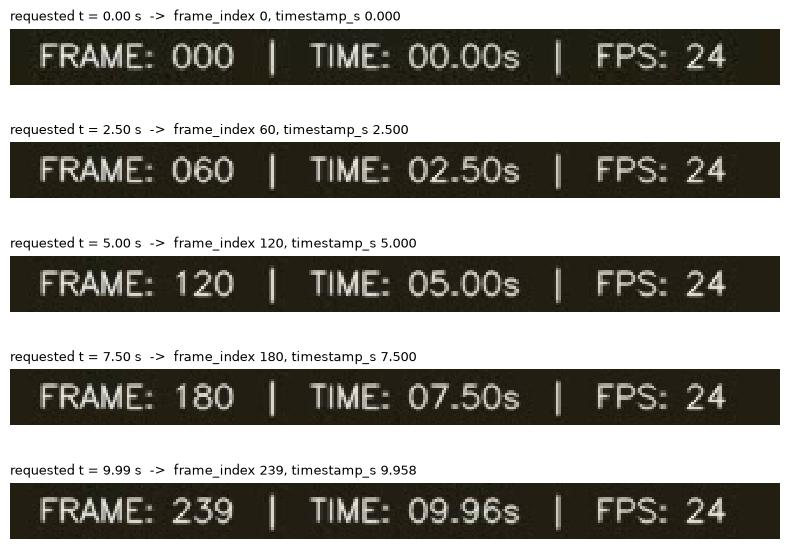

In [18]:
OVERLAY_REGION = (slice(336, 360), slice(0, 330))  # bottom-left text strip, chosen by inspection
requested_times = [0.0, 2.5, 5.0, 7.5, 9.99]

fig, axes = plt.subplots(len(requested_times), 1, figsize=(8, 1.2 * len(requested_times)))
for ax, t in zip(axes, requested_times):
    record = read_frame_at_time(SYNTHETIC_VIDEO, t)
    ax.imshow(cv2.cvtColor(record["image"][OVERLAY_REGION], cv2.COLOR_BGR2RGB), interpolation="nearest")
    ax.set_title(f"requested t = {t:.2f} s  ->  frame_index {record['frame_index']}, "
                 f"timestamp_s {record['timestamp_s']:.3f}", fontsize=9, loc="left")
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "timestamp_access_overlay_check.png", dpi=100)
plt.show()

Each overlay should show the same frame number as the title, and a time equal to `frame_index / 24` (the overlay prints two decimals).

**Why convert the time ourselves?** OpenCV can also seek by time with `CAP_PROP_POS_MSEC`, but its rounding rule is not documented. The comparison below uses `car-detection.mp4` (12.5 FPS), where some requested times fall exactly on half-frame boundaries.

In [19]:
def seek_by_msec_index(path, t_seconds: float) -> int:
    # Which frame does OpenCV's own time-based seek return? Identified by its hash.
    with open_video(path) as capture:
        capture.set(cv2.CAP_PROP_POS_MSEC, t_seconds * 1000)
        ok, image = capture.read()
    return reference[path.name]["hashes"].index(frame_hash(image)) if ok else None


overhead_fps = reference[OVERHEAD_VIDEO.name]["meta"]["fps"]
msec_comparison = []
print("t (s) | frame on screen (our rule) | OpenCV POS_MSEC seek")
for t in [0.5, 1.0, 2.0, 5.0, 7.3]:
    ours = frame_index_at_time(t, overhead_fps)
    theirs = seek_by_msec_index(OVERHEAD_VIDEO, t)
    msec_comparison.append({"t": t, "ours": ours, "opencv": theirs})
    print(f"{t:5.2f} | {ours:26d} | {theirs:20d}{'   <- differs' if ours != theirs else ''}")

t (s) | frame on screen (our rule) | OpenCV POS_MSEC seek
 0.50 |                          6 |                    6
 1.00 |                         12 |                   13   <- differs
 2.00 |                         25 |                   25
 5.00 |                         62 |                   63   <- differs
 7.30 |                         91 |                   91


Where the columns differ, the requested time lies between two frames. At 12.5 FPS, *t* = 1.0 s falls between frame 12 (0.96 s) and frame 13 (1.04 s). Frame 12 is on screen at 1.0 s, so our rule returns 12. OpenCV returned 13, consistent with rounding `t · fps` half up.

Neither answer is wrong, but they differ, and an event timestamp must map to one well-defined frame. The project therefore uses `frame_index_at_time` and seeks by **frame index**, which was verified exact above.

**Frames at selected timestamps of the primary sample** (task 9 on real footage):

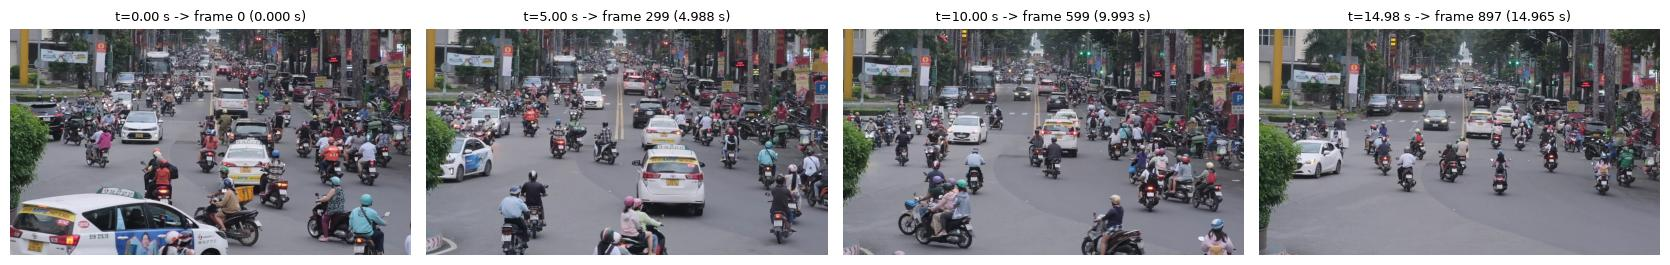

In [20]:
selected_times = [0.0, 5.0, 10.0, 14.98]
fig, axes = plt.subplots(1, len(selected_times), figsize=(4.2 * len(selected_times), 2.9))
for ax, t in zip(axes, selected_times):
    record = read_frame_at_time(SAMPLE_VIDEO, t)
    ax.imshow(cv2.cvtColor(record["image"], cv2.COLOR_BGR2RGB))
    ax.set_title(f"t={t:.2f} s -> frame {record['frame_index']} ({record['timestamp_s']:.3f} s)", fontsize=9)
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "sample_frames_at_timestamps.png", dpi=80)
plt.show()

## 11. End of video, invalid files, and resource cleanup

We now feed the helpers inputs they must reject or handle. The bad files are generated in `outputs/01_video_reading/invalid_inputs/` so the notebook is self-contained:

- a text file renamed to `.mp4`;
- an empty `.mp4`;
- a **truncated** copy of the sample, containing only the first half of its bytes, as an interrupted download or copy would leave it.

OpenCV/FFmpeg may print their own log lines for these files. Our code relies on the exceptions and warnings, not on those logs.

In [21]:
INVALID_DIR = OUTPUT_DIR / "invalid_inputs"
INVALID_DIR.mkdir(exist_ok=True)

text_file = INVALID_DIR / "not_a_video.mp4"
text_file.write_text("this is not a video")
empty_file = INVALID_DIR / "empty.mp4"
empty_file.write_bytes(b"")
truncated_file = INVALID_DIR / "truncated_half.mp4"
sample_bytes = SAMPLE_VIDEO.read_bytes()
truncated_file.write_bytes(sample_bytes[: len(sample_bytes) // 2])

invalid_cases = {
    "missing file": DATA_DIR / "does_not_exist.mp4",
    "directory": DATA_DIR,
    "text file": text_file,
    "empty file": empty_file,
    "truncated file": truncated_file,
}


def try_read_all(path) -> dict:
    # Read a whole video with the helpers; report what happened instead of crashing.
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        try:
            meta = read_video_metadata(path)
            decoded = sum(1 for _ in iter_frames(path))
            outcome = f"opened; header reports {meta['reported_frame_count']} frames, decoded {decoded}"
        except (FileNotFoundError, RuntimeError) as error:
            outcome = f"{type(error).__name__}: {error}"
    messages = [str(w.message) for w in caught]
    return {"outcome": outcome, "warnings": messages}


invalid_results = {label: try_read_all(path) for label, path in invalid_cases.items()}
for label, result in invalid_results.items():
    print(f"{label:<15} -> {result['outcome']}")
    for message in result["warnings"]:
        print(f"{'':<18}WARNING: {message}")

[mov,mp4,m4a,3gp,3g2,mj2 @ 0x58187634f500] moov atom not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x58187634f500] moov atom not found


missing file    -> FileNotFoundError: Video file not found (or not a file): /workspace/traffic-violation-detection-system/data/does_not_exist.mp4
directory       -> FileNotFoundError: Video file not found (or not a file): /workspace/traffic-violation-detection-system/data
text file       -> RuntimeError: OpenCV could not open the video: /workspace/traffic-violation-detection-system/outputs/01_video_reading/invalid_inputs/not_a_video.mp4
empty file      -> RuntimeError: OpenCV could not open the video: /workspace/traffic-violation-detection-system/outputs/01_video_reading/invalid_inputs/empty.mp4
truncated file  -> opened; header reports 900 frames, decoded 420


[mov,mp4,m4a,3gp,3g2,mj2 @ 0x58187634f500] stream 1, offset 0x570e24: partial file
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x58187634f500] stream 1, offset 0x57101d: partial file


The truncated file is the dangerous case. It **opens successfully** and its header still claims the full frame count, because the index lives at the start of this MP4, but only part of the video can be decoded. A reader that trusted `CAP_PROP_FRAME_COUNT` would report a full video; ours stops when decoding stops and warns about the gap.

**End of video and out-of-range requests:**

In [22]:
last_index = reference[SAMPLE_VIDEO.name]["decoded"] - 1
last = read_frame_at(SAMPLE_VIDEO, last_index)
print(f"last frame {last_index}: ok, timestamp {last['timestamp_s']:.3f} s")

end_of_video = {}
for label, index in [("one past the end", last_index + 1), ("far past the end", last_index + 100)]:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        try:
            read_frame_at(SAMPLE_VIDEO, index)
            end_of_video[label] = "returned a frame (unexpected)"
        except IndexError as error:
            end_of_video[label] = f"IndexError: {error}"
    print(f"{label:<17} (frame {index}): {end_of_video[label]}"
          + (f" | warning: {caught[0].message}" if caught else ""))

beyond_stop = sum(1 for _ in iter_frames(SAMPLE_VIDEO, start=last_index - 2, stop=last_index + 50))
print(f"iter_frames with stop beyond the end yields {beyond_stop} frames (the last 3), without error")

last frame 899: ok, timestamp 14.998 s


one past the end  (frame 900): IndexError: Frame 900 is beyond the end of video-test.mp4


far past the end  (frame 999): IndexError: Frame 999 is beyond the end of video-test.mp4 | warning: video-test.mp4: cannot seek to frame 999; the video ends at frame 900


iter_frames with stop beyond the end yields 3 frames (the last 3), without error


**Resource cleanup.** `open_video` must release the capture in every situation: a normal exit, an exception inside the `with` block, and a generator abandoned after its first frame. We keep a reference to the capture object to inspect it afterwards.

In [23]:
with open_video(SAMPLE_VIDEO) as capture:
    held = capture
released_normally = not held.isOpened()

try:
    with open_video(SAMPLE_VIDEO) as capture:
        held = capture
        raise ValueError("simulated failure inside the with-block")
except ValueError:
    pass
released_after_exception = not held.isOpened()

print("released after normal exit  :", released_normally)
print("released after an exception :", released_after_exception)

released after normal exit  : True
released after an exception : True


## 12. Validation

All checks below re-use results computed in this run. A failure stops the notebook.

In [24]:
checks = {}
for name, ref in reference.items():
    checks[f"{name}: decoded count == header count"] = ref["decoded"] == ref["meta"]["reported_frame_count"]
    checks[f"{name}: indices 0..N-1 without gaps (no skipped frames)"] = ref["indices_contiguous"]
    checks[f"{name}: timestamps strictly increasing"] = ref["timestamps_increasing"]
    checks[f"{name}: timestamps == index / fps (< 0.001 ms)"] = ref["max_timestamp_error_ms"] < 1e-3
    checks[f"{name}: random access returns the exact frame"] = not random_access[name]["mismatches"]

checks[f"step={STEP} returns every {STEP}th frame with identical pixels"] = step_indices_ok and step_pixels_ok
checks["frame_index_at_time uses the on-screen rule"] = (
    frame_index_at_time(1.0, 12.5) == 12 and frame_index_at_time(0.08, 12.5) == 1 and frame_index_at_time(0.0, 24) == 0
)
checks["missing file / directory raise FileNotFoundError"] = all(
    invalid_results[k]["outcome"].startswith("FileNotFoundError") for k in ("missing file", "directory"))
checks["text / empty file raise RuntimeError"] = all(
    invalid_results[k]["outcome"].startswith("RuntimeError") for k in ("text file", "empty file"))
checks["truncated file triggers the early-end warning"] = any(
    "video ended at frame" in m for m in invalid_results["truncated file"]["warnings"])
checks["reads past the end raise IndexError"] = all(v.startswith("IndexError") for v in end_of_video.values())
checks["capture released after normal exit and after exception"] = released_normally and released_after_exception

for name, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")
assert all(checks.values()), "One or more checks failed - see above"

[PASS] video-test.mp4: decoded count == header count
[PASS] video-test.mp4: indices 0..N-1 without gaps (no skipped frames)
[PASS] video-test.mp4: timestamps strictly increasing
[PASS] video-test.mp4: timestamps == index / fps (< 0.001 ms)
[PASS] video-test.mp4: random access returns the exact frame
[PASS] traffic_sample.mp4: decoded count == header count
[PASS] traffic_sample.mp4: indices 0..N-1 without gaps (no skipped frames)
[PASS] traffic_sample.mp4: timestamps strictly increasing
[PASS] traffic_sample.mp4: timestamps == index / fps (< 0.001 ms)
[PASS] traffic_sample.mp4: random access returns the exact frame
[PASS] car-detection.mp4: decoded count == header count
[PASS] car-detection.mp4: indices 0..N-1 without gaps (no skipped frames)
[PASS] car-detection.mp4: timestamps strictly increasing
[PASS] car-detection.mp4: timestamps == index / fps (< 0.001 ms)
[PASS] car-detection.mp4: random access returns the exact frame
[PASS] step=5 returns every 5th frame with identical pixels
[P

## 13. Performance summary and saved report

Timings are from the machine that ran this notebook. Video decoding runs on the CPU, even on the GPU server, and timings change between runs and machines. They are recorded to budget later stages.

In [25]:
sample_meta = reference[SAMPLE_VIDEO.name]["meta"]
sequential_ms = reference[SAMPLE_VIDEO.name]["seconds"] / reference[SAMPLE_VIDEO.name]["decoded"] * 1000
print(f"{SAMPLE_VIDEO.name} ({sample_meta['width']}x{sample_meta['height']} @ {sample_meta['fps']:.2f} FPS)")
print(f"  real-time budget per frame          : {1000 / sample_meta['fps']:.1f} ms")
print(f"  sequential read (+ MD5 hashing)     : {sequential_ms:.1f} ms per frame")
print(f"  random access (seek + decode)       : {random_access[SAMPLE_VIDEO.name]['ms_per_access']:.1f} ms per frame")
print(f"  step={STEP}: iter_frames vs naive read  : {grab_seconds:.2f} s vs {read_seconds:.2f} s")

report = {
    "videos": {name: {**ref["meta"], "decoded_frame_count": ref["decoded"],
                      "max_timestamp_error_ms": ref["max_timestamp_error_ms"]} for name, ref in reference.items()},
    "position_semantics": {
        "POS_FRAMES_after_read": "index of the next frame",
        "POS_MSEC_after_read": "timestamp of the frame just returned",
    },
    "random_access": random_access,
    "opencv_msec_seek_vs_on_screen_rule": msec_comparison,
    "invalid_inputs": invalid_results,
    "end_of_video": end_of_video,
    "timings_s": {"step5_iter_frames": grab_seconds, "step5_naive_read": read_seconds},
    "checks": checks,
}
report_path = OUTPUT_DIR / "video_reading_report.json"
report_path.write_text(json.dumps(report, indent=2))
assert json.loads(report_path.read_text())["checks"] == checks
print("Wrote", report_path.relative_to(PROJECT_ROOT))

video-test.mp4 (1920x1080 @ 59.94 FPS)
  real-time budget per frame          : 16.7 ms
  sequential read (+ MD5 hashing)     : 11.2 ms per frame
  random access (seek + decode)       : 229.0 ms per frame
  step=5: iter_frames vs naive read  : 2.35 s vs 3.05 s
Wrote outputs/01_video_reading/video_reading_report.json


## Results

**Verified in this run, on all three videos:**

- **No skipped or repeated frames.** Sequential reading returns every frame exactly once. Indices run 0 … N−1 without gaps, and the decoded count equals the header count.
- **Position semantics.** After `read()`, `CAP_PROP_POS_FRAMES` is the index of the *next* frame, and `CAP_PROP_POS_MSEC` is the timestamp of the frame *just returned*.
- **Timestamps.** The decoder's timestamps equal `index / fps` (constant frame rate) and strictly increase.
- **Random access by frame index is exact.** All 47 sampled seeks across the three videos returned the bit-identical frame.
- **Stepping.** `step` returns exactly every *k*-th frame with identical pixels. Using `grab()` for skipped frames was 1.3–1.9× faster than reading every frame (step = 5): 1.9× on the development machine, 1.3× on the GPU server, whose CPU decodes faster.
- **Access by time.** `frame_index_at_time` (frame on screen at *t*) was confirmed against the burned-in overlay of the synthetic clip at five times. OpenCV's own `CAP_PROP_POS_MSEC` seek follows a different rounding: it differed at 2 of 5 test times on the 12.5 FPS clip. The project therefore seeks by frame index.
- **Invalid inputs.**
  - Missing path or directory → `FileNotFoundError`.
  - Text or empty file → `RuntimeError`.
  - Truncated file → it opens and its header still claims 900 frames, but only 420 decode. `iter_frames` warns about the gap instead of finishing silently.
- **Out-of-range access.** Reads past the end raise `IndexError`.
- **Cleanup.** The capture is released after a normal exit and after an exception.

**Performance (video decoding runs on the CPU; varies between runs and machines).** On the 1080p sample, a random access costs on the order of 200 ms, including opening the file, on both the development machine and the GPU server. Sequential decoding needs only a few ms per frame (Notebook 00: about 300 frames/s locally, about 670 frames/s on the GPU server), against a real-time budget of 16.7 ms per frame. Pipelines should therefore iterate sequentially and seek only for sparse evidence frames.

## Limitations

- **Constant frame rate only.** Only files with a constant frame rate were tested. `timestamp_s` comes from the decoder and should also be correct for variable frame rate, but that is unverified. `frame_index_at_time` assumes a constant rate.
- **One build, three files.** Seek exactness was verified for this OpenCV build (5.0.0, FFmpeg backend) and these three encodings, on the development machine and the GPU server. Re-run the tests for any new footage or OpenCV version.
- **Video identity.** `video_id` is the file name without extension, which is not unique across folders. Revisit this when footage comes from several sources.
- **Streams not covered.** Live camera streams (e.g. RTSP) have no reliable frame count and no seeking; they are out of scope for now.
- **Camera drift.** The drift found in Notebook 00 is not a reading problem, so it is not addressed here.

## Conclusion

**Completion criterion** — *the notebook reliably reads and visualizes video frames without unintentionally skipping frames or mismanaging the capture object's position*: **met**.

- Every access path (sequential, stepped, random by index, random by time) was checked frame-by-frame against reference hashes.
- The capture position is handled by giving each call its own capture and keeping our own frame counter.

**Readiness for integration: done.**

- The validated functions now live in `src/traffic_violation_detection/video.py`, and this notebook imports them from there.
- The checks of section 12 also run as `pytest` tests in `tests/test_video.py` (43 tests, all passing on the GPU server).
- Later notebooks import from the same module, so the reading logic exists in one place only.

**Next step: Notebook 02** — object detection, consuming frames from `iter_frames`.